# Present-day subhalo positions

Projected $z=0$ positions of the subhalos in an evolved SatGen tree, colored by order $k$.
Each subhalo is drawn with a size set by its Green & van den Bosch (2019) tidal radius. The host $R_{\rm vir}$ is the dashed circle.

* Positions come from `Tree_Vis.cartesian_stitched`. Higher-order subhalos are chained back through their parents, so every position is host-centric.
* The tidal radius is **capped at the subhalo's own virial radius at accretion**, $r_{\rm vir,acc}$ (see the notes below the movie).
* The tidal radius is recomputed here with the same definition used in `jsm_SubEvo_masscut.py`:
  * the subhalo is a `Green` profile built from its accretion mass, concentration, $\Delta_{\rm vir}(z_{\rm acc})$ and $z_{\rm acc}$, then stripped to its $z=0$ mass;
  * `ev.ltidal(..., choice='King62')` is solved in the potential of the subhalo's **immediate parent** (host NFW for $k=1$, parent's stripped `Green` profile for $k>1$), using the native parent-relative $(R,\phi,z)$ coordinates.
* `ltidal` returns kpc. It is bracketed between `cfg.Rres` (0.001 kpc) and $9.999\,r_{\rm vir,acc}$ of the subhalo, and falls back to `cfg.Rres` if there is no root.

In [1]:
import sys
sys.path.insert(0, '/Users/jsmonzon/Research/SatGen/mcmc/src/')

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import EllipseCollection
from matplotlib.lines import Line2D

import jsm_visualize as jv
from jsm_visualize import profiles, cfg, ev

%matplotlib inline

In [2]:
tree_file = '/Users/jsmonzon/Research/MassSpec/data/local_trees/evolved_trees/tree_14.0.npz'
mass_threshold = 1e9  # Msun, sets the 'massive' / 'surviving' regimes in Tree_Reader.compute_regimes

tree = jv.Tree_Vis(file=tree_file, verbose=False, mass_threshold=mass_threshold)

print(f"host M = {tree.mass[0, 0]:.3e} Msun, Rvir = {tree.VirialRadius[0, 0]:.1f} kpc")
print(f"{tree.orbit_mask[:, 0].sum()} subhalos alive at z=0 out of {tree.Nhalo - 1}")
print(f"{tree.regime_masks['surviving'][:, 0].sum()} alive with m(z=0) > {mass_threshold:.0e} Msun")

host M = 1.000e+14 Msun, Rvir = 1201.8 kpc
6209 subhalos alive at z=0 out of 15700
1948 alive with m(z=0) > 1e+09 Msun


## Tidal radius

In [3]:
def subhalo_green(tree, ind, iz):
    """Green profile of subhalo `ind`, stripped to its mass at snapshot `iz`."""
    s = profiles.Green(tree.acc_mass[ind], tree.acc_concentration[ind],
                       Delta=cfg.Dvsample[tree.acc_index[ind]], z=tree.acc_redshift[ind])
    s.update_mass(tree.mass[ind, iz])
    return s


def compute_tidal_radius(tree, iz=0, choice='King62', mask=None, cap=True):
    """
    Tidal radius [kpc] of every subhalo alive at snapshot `iz` (NaN otherwise),
    optionally restricted to `mask` (Nhalo,),
    matching jsm_SubEvo_masscut: the subhalo Green profile in its immediate parent's
    potential, evaluated at the parent-relative phase-space coordinates.

    cap=True limits r_t to the subhalo's own virial radius at accretion (Green.rh).
    When ev.ltidal finds no root because the tides are too weak (m(l)/l^3 > RHS all the
    way out to its 9.999 rh bracket) it returns cfg.Rres; those cases are set to rh too.
    """
    rhs_func = ev.lt_King62_RHS if choice == 'King62' else ev.lt_Tormen98_RHS
    host = profiles.NFW(tree.mass[0, iz], tree.concentration[0, iz],
                        Delta=cfg.Dvsample[iz], z=tree.redshift[iz])
    parents = {}
    rt = np.full(tree.Nhalo, np.nan)
    sel = tree.orbit_mask[:, iz] if mask is None else tree.orbit_mask[:, iz] & mask
    for ind in np.where(sel)[0]:
        ip = tree.ParentID[ind, iz]
        if ip == 0:
            p = host
        else:
            if ip not in parents:
                parents[ip] = subhalo_green(tree, ip, iz)
            p = parents[ip]
        s = subhalo_green(tree, ind, iz)
        xv = tree.coordinates[ind, iz]
        lt = ev.ltidal(s, p, xv, choice=choice)
        if cap:
            if lt <= cfg.Rres and ev.Findlt(9.999 * s.rh, s, rhs_func(p, xv)) > 0:
                lt = s.rh  # weak tides: no root inside the bracket
            lt = min(lt, s.rh)
        rt[ind] = lt
    return rt


tree.rtidal = compute_tidal_radius(tree, iz=0)                 # capped at r_vir,acc, used for all plots
tree.rtidal_raw = compute_tidal_radius(tree, iz=0, cap=False)  # SatGen's definition, for the check below

alive = tree.orbit_mask[:, 0]
n_capped = np.sum(alive & (tree.rtidal != tree.rtidal_raw))
print(f"{n_capped} of {alive.sum()} alive subhalos are capped at r_vir,acc at z=0")

1842 of 6209 alive subhalos are capped at r_vir,acc at z=0


Sanity check on the uncapped values (`cap=False`). SatGen stores `lt` in `VirialRadius[id, :]` after accretion. That value is computed one step earlier, with the pre-stripping mass, so the ratio should sit close to 1 with some scatter.

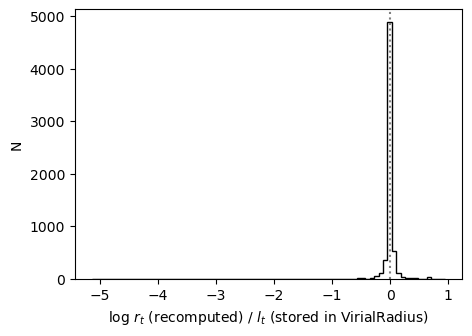

k=1: N= 5466, median ratio = 1.004, median r_t = 11.00 kpc (raw), 9.89 kpc (capped)
k=2: N=  735, median ratio = 1.007, median r_t = 3.40 kpc (raw), 3.73 kpc (capped)
k=3: N=    8, median ratio = 1.001, median r_t = 1.08 kpc (raw), 3.51 kpc (capped)


In [4]:
ratio = tree.rtidal_raw[alive] / tree.VirialRadius[alive, 0]

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.hist(np.log10(ratio), bins=80, histtype='step', color='k')
ax.axvline(0, ls=':', color='grey')
ax.set_xlabel('log $r_t$ (recomputed) / $l_t$ (stored in VirialRadius)')
ax.set_ylabel('N')
plt.show()

for k in np.unique(tree.order[alive, 0]):
    sel = tree.order[alive, 0] == k
    print(f"k={k}: N={sel.sum():5d}, median ratio = {np.nanmedian(ratio[sel]):.3f}, "
          f"median r_t = {np.nanmedian(tree.rtidal_raw[alive][sel]):.2f} kpc (raw), "
          f"{np.nanmedian(tree.rtidal[alive][sel]):.2f} kpc (capped)")

## Plotting routine

* `regime`: any key of `tree.regime_masks` (`'total'`, `'massive'`, `'surviving'`, `'rvir'`, `'rvir_surv'`, `'artificial'`). `'total'` means every subhalo alive at $z=0$, with no mass cut.
* `size_mode='physical'`: circles whose radius is $r_t$ in kpc, drawn to scale with $R_{\rm vir}$.
* `size_mode='scaled'`: scatter markers whose area goes as $\log r_t$. This is easier to read when $r_t$ spans many decades.
* `scale`: half-width of the plot, in units of $R_{\rm vir}$ at that snapshot. `extent` overrides it with a fixed half-width in kpc.
* `size_mode='mass'`: scatter markers whose area is proportional to the bound mass $m(t)$: `size_ref` pt$^2$ at `mass_ref`, with no clipping and the same normalization in every frame. A size key is drawn in the lower right.
* Colors follow the `Set1` order map used in `make_orbit_movie` / `plot_acc_tree`.

In [5]:
PROJECTIONS = {'xy': (0, 1), 'xz': (0, 2), 'yz': (1, 2)}
AXIS_LABELS = ['x', 'y', 'z']
MAX_LEVELS = 5
ORDER_CMAP = plt.cm.get_cmap('Set1', MAX_LEVELS + 1)


def plot_subhalo_projection(tree, rt, proj='xy', iz=0, regime='total', size_mode='physical',
                            scale=1.5, extent=None, alpha=0.5, min_size=0.5, max_size=60,
                            mass_ref=1e9, size_ref=1.0, ax=None):

    i, j = PROJECTIONS[proj]
    sel = tree.regime_masks[regime][:, iz]
    if rt is not None:
        sel = sel & np.isfinite(rt)
    inds = np.where(sel)[0]
    m = tree.mass[inds, iz]
    order_by = m if size_mode == 'mass' else rt[inds]
    inds, m = inds[np.argsort(order_by)[::-1]], m[np.argsort(order_by)[::-1]]  # draw the largest first so small ones sit on top

    x = tree.cartesian_stitched[inds, iz, i]
    y = tree.cartesian_stitched[inds, iz, j]
    k = tree.order[inds, iz]
    colors = ORDER_CMAP(k)
    rvir = tree.VirialRadius[0, iz]

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 7))

    if size_mode == 'physical':
        d = 2 * rt[inds]
        ax.add_collection(EllipseCollection(d, d, np.zeros_like(d), units='xy', offsets=np.c_[x, y],
                                            offset_transform=ax.transData, facecolors=colors,
                                            edgecolors=colors, linewidths=0.3, alpha=alpha))
    elif size_mode == 'scaled':
        lr = np.log10(rt[inds])
        span = np.ptp(lr) if lr.size else 0.0
        s = min_size + (lr - lr.min()) / span * (max_size - min_size) if span > 0 else np.full(lr.size, max_size)
        ax.scatter(x, y, s=s, c=colors, alpha=alpha, edgecolors='none')
    elif size_mode == 'mass':
        # marker area [pt^2] proportional to bound mass, fixed normalization (no clipping, same in every frame)
        ax.scatter(x, y, s=size_ref * m / mass_ref, c=colors, alpha=alpha, edgecolors='none')
    else:
        raise ValueError("size_mode must be 'physical', 'scaled' or 'mass'")

    ax.add_patch(plt.Circle((0, 0), rvir, color='k', fill=False, lw=1.2, ls='--'))

    half = scale * rvir if extent is None else extent  # extent: fixed half-width in kpc
    ax.set_xlim(-half, half)
    ax.set_ylim(-half, half)
    ax.set_aspect('equal')
    ax.set_xlabel(f'{AXIS_LABELS[i]} (kpc)')
    ax.set_ylabel(f'{AXIS_LABELS[j]} (kpc)')
    ax.set_title(f'z = {tree.redshift[iz]:.2f}   {proj} projection   ({regime}, N = {inds.size})')

    handles = [Line2D([], [], marker='o', ls='', color=ORDER_CMAP(kk), label=f'k = {kk}')
               for kk in np.unique(k)]
    handles.append(Line2D([], [], ls='--', color='k', label=f'$R_{{\\rm vir}}$ = {rvir:.0f} kpc'))
    ax.add_artist(ax.legend(handles=handles, loc='upper right', fontsize=9, framealpha=0.9))

    if size_mode == 'mass':
        size_handles = [Line2D([], [], marker='o', ls='', color='grey', alpha=alpha,
                               markersize=np.sqrt(size_ref * mm / mass_ref), label=f'$10^{{{np.log10(mm):.0f}}}\,M_\odot$')
                        for mm in (1e9, 1e10, 1e11, 1e12)]
        ax.legend(handles=size_handles, loc='lower right', fontsize=9, framealpha=0.9, labelspacing=2.0, borderpad=1.2, handletextpad=1.6)
    return ax

## Figures: x–y, x–z, y–z

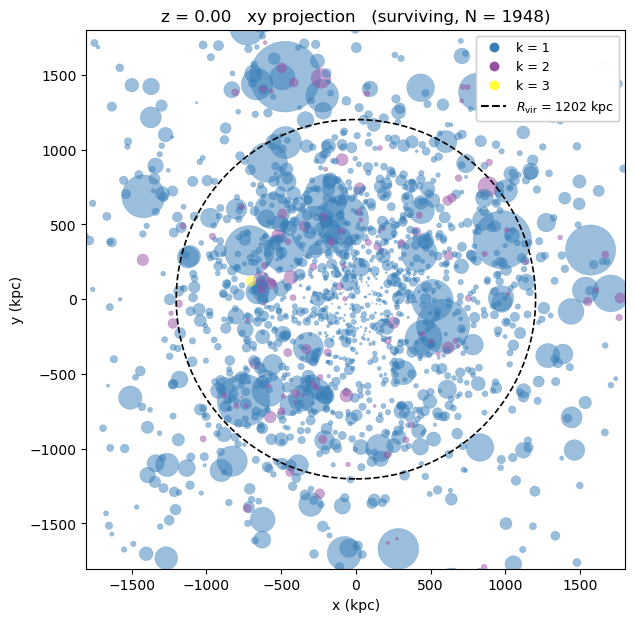

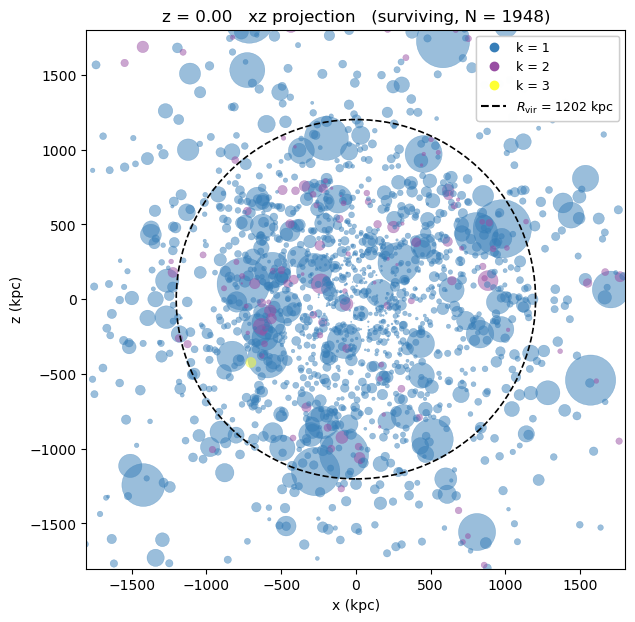

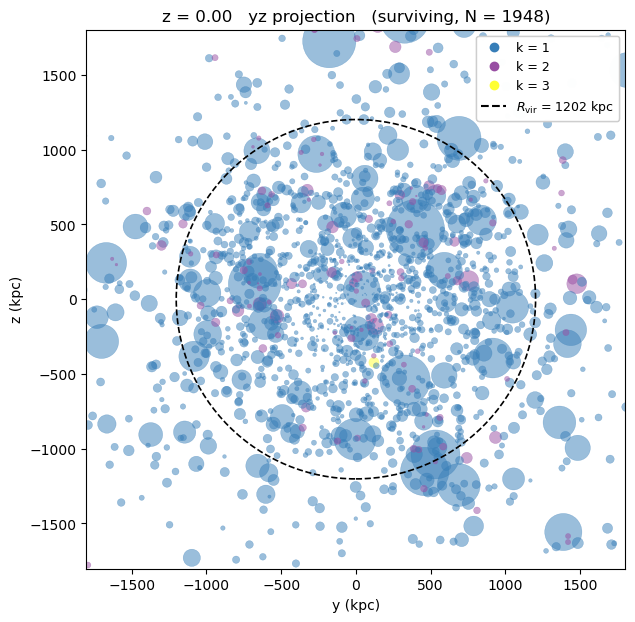

In [6]:
regime = 'surviving'    # alive at z=0 with m(z=0) > mass_threshold; try 'rvir_surv', 'artificial', 'total' (no mass cut)
size_mode = 'physical'  # or 'scaled'
scale = 1.5             # plot half-width in units of Rvir

for proj in ('xy', 'xz', 'yz'):
    plot_subhalo_projection(tree, tree.rtidal, proj=proj, regime=regime, size_mode=size_mode, scale=scale)
    plt.show()

### Same projections with scaled markers

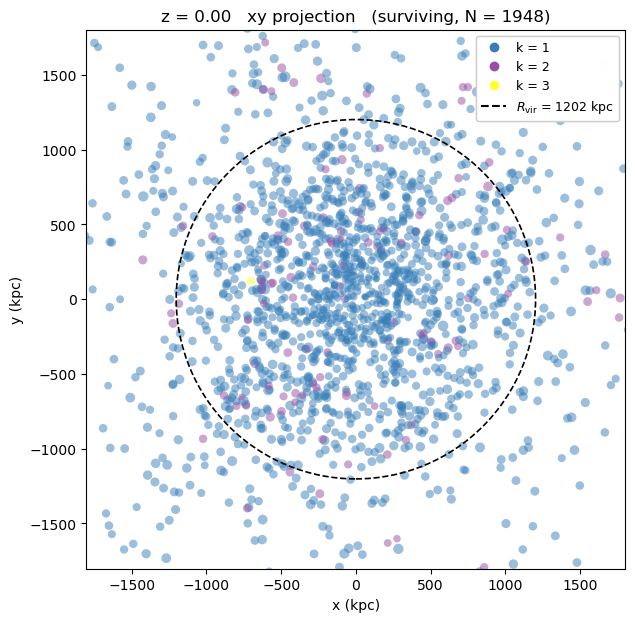

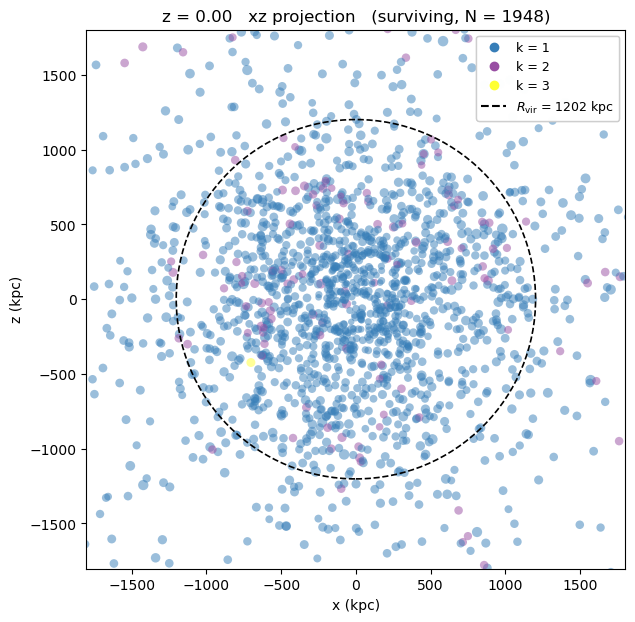

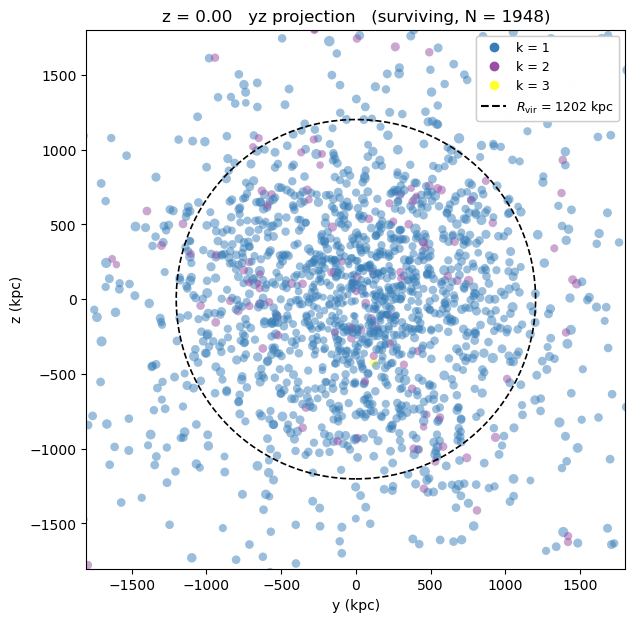

In [7]:
for proj in ('xy', 'xz', 'yz'):
    plot_subhalo_projection(tree, tree.rtidal, proj=proj, regime=regime, size_mode='scaled', scale=scale)
    plt.show()

## Movie

The same routine is drawn at every snapshot, from the first snapshot with a selected subhalo down to $z=0$, with all three projections side by side.

* The tidal radius is recomputed at each snapshot with `compute_tidal_radius`: each subhalo's `Green` profile is stripped to $m(t)$, and its parent's potential is taken at $t$ (for the host, NFW with $M(t)$, $c(t)$, $\Delta_{\rm vir}(z)$).
* `movie_regime = 'massive'` keeps subhalos with $m(t) >$ `mass_threshold` at time $t$. `'surviving'` would also require $m(z=0) >$ `mass_threshold`, which hides every subhalo that later disrupts.
* `box='fixed'` keeps the frame at `scale` $\times R_{\rm vir}(z=0)$, so the host visibly grows. `box='rvir'` rescales each frame to `scale` $\times R_{\rm vir}(t)$, which is better for seeing structure at high $z$.
* `stride` skips snapshots (1 = every snapshot).

In [8]:
import imageio


def compute_tidal_radius_history(tree, mask, choice='King62'):
    """Tidal radius [kpc], shape (Nhalo, Nsnap); NaN wherever `mask` is False or the subhalo is not alive."""
    rt = np.full(tree.mass.shape, np.nan)
    for iz in np.where(mask.any(axis=0))[0]:
        rt[:, iz] = compute_tidal_radius(tree, iz=iz, choice=choice, mask=mask[:, iz])
    return rt


def make_projection_movie(tree, rt_hist, video_path, projs=('xy', 'xz', 'yz'), regime='massive',
                          box='fixed', scale=1.5, stride=1, fps=15, dpi=100, **plot_kw):

    mask = tree.regime_masks[regime]
    snaps = np.where(mask.any(axis=0))[0][::-1][::stride]  # high z -> z=0
    if snaps[-1] != 0:
        snaps = np.append(snaps, 0)

    extent0 = scale * tree.VirialRadius[0, 0]
    fig, axes = plt.subplots(1, len(projs), figsize=(6.4 * len(projs), 7.2), dpi=dpi)
    axes = np.atleast_1d(axes)
    fig.subplots_adjust(left=0.06, right=0.98, bottom=0.08, top=0.88, wspace=0.25)

    with imageio.get_writer(video_path, fps=fps) as writer:
        for iz in snaps:
            for ax, proj in zip(axes, projs):
                ax.clear()
                plot_subhalo_projection(tree, rt_hist[:, iz], proj=proj, iz=iz, regime=regime, scale=scale,
                                        extent=extent0 if box == 'fixed' else None, ax=ax, **plot_kw)
                ax.set_title(f'{proj}   (N = {mask[:, iz].sum()})')
            fig.suptitle(f't = {tree.CosmicTime[iz]:.2f} Gyr    z = {tree.redshift[iz]:.2f}', fontsize=14)
            fig.canvas.draw()
            writer.append_data(np.asarray(fig.canvas.buffer_rgba())[..., :3])

    plt.close(fig)
    print(f'wrote {len(snaps)} frames to {video_path}')

In [9]:
movie_regime = 'massive'

tree.rtidal_hist = compute_tidal_radius_history(tree, tree.regime_masks[movie_regime])

In [10]:
import os
from IPython.display import Video

os.makedirs('movies', exist_ok=True)
tree_name = os.path.basename(tree_file).replace('.npz', '')
video_path = f'movies/{tree_name}_positions_{movie_regime}_rtidal.mp4'

make_projection_movie(tree, tree.rtidal_hist, video_path, regime=movie_regime,
                      box='fixed', size_mode='physical', scale=1.5, stride=1, fps=15)
Video(video_path, width=960)

wrote 299 frames to movies/tree_14.0_positions_massive_rtidal.mp4


### Notes on the tidal-radius sizes

* At a **fixed orbital position**, the Green & van den Bosch transfer function makes $r_t$ shrink monotonically as $f_b$ drops: stripping lowers $m(<l)$ at every $l$, and the King62 condition $m(l_t)/l_t^3 = {\rm RHS}(\text{orbit})$ then pushes $l_t$ inward.
* The large circles that grow in the movie are subhalos moving **away from their parent** (mostly splashback orbits out to several $R_{\rm vir}$), where the RHS drops roughly as $r^{-3}$. Their raw $r_t$ can exceed the subhalo's own $r_{\rm vir,acc}$, so it no longer measures the physical extent of the bound mass. **This is why `compute_tidal_radius` caps $r_t$ at $r_{\rm vir,acc}$ by default.**
* When the RHS falls below $m(10\,r_{\rm vir,acc})/(10\,r_{\rm vir,acc})^3$, `ev.ltidal` finds no root and returns `cfg.Rres` = 0.001 kpc. With `cap=True` these weak-tide cases are set to $r_{\rm vir,acc}$ instead, so the circle no longer vanishes.

## Movie sized by bound mass

In [11]:
video_path_mass = f'movies/{tree_name}_positions_{movie_regime}_mass.mp4'

make_projection_movie(tree, tree.rtidal_hist, video_path_mass, regime=movie_regime,
                      box='fixed', size_mode='mass', mass_ref=1e9, size_ref=1.0, scale=1.5, stride=1, fps=15)
Video(video_path_mass, width=960)

wrote 299 frames to movies/tree_14.0_positions_massive_mass.mp4
